# 02. A plain PINN on problems S and A

**Milestone M2** (see SPEC.md): train a plain physics-informed neural network on the smooth case S, then on the step case A, and measure it against the analytic reference fields from notebook 01.

**Acceptance criteria.** Relative L2 error on S below 1e-3; behavior on A, including failures, documented with plots.

**What "plain" means here.** Equal weights on the PDE residual, boundary and initial-condition terms; no hard-coded boundary conditions; no adaptive sampling; no causal training. Those are the M3 experiments, and they need this notebook as their baseline.

**Honest notes on how the numbers were produced**

- The optimizer budget (2000 Adam steps, then 2000 L-BFGS iterations) was fixed after two probe runs on seed 0. A first probe with only 300 L-BFGS iterations reached 5.9e-3 on S with the error still falling, so the L-BFGS budget was raised. The same budget was then used for every run reported here, including problem A.
- Wall-clock times in the tables are **not clean benchmarks**: two training jobs shared two CPU cores while they ran. Use them for rough scale only.
- Three seeds in float32 for each problem; float64 is a single seed (seed 0). Float64 runs were roughly two to three times slower here.

In [1]:
import pickle, os, time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
TAU_MAX = 0.5

## 1. The PINN

A plain PINN with equal loss weights, as specified in SPEC.md section 4: a 4 x 64 tanh network, autograd for the PDE residual, uniform random collocation points resampled at every Adam step, then L-BFGS on one fixed point set. Nothing here is tuned for problem A on purpose; M3 is where the improvements go.

In [2]:
import time
import numpy as np
import torch
import torch.nn as nn

TAU_MAX = 0.5

PROBLEMS = {
    # S: smooth sine initial profile, zero boundaries
    "S": dict(ic=lambda xi: torch.sin(np.pi * xi), bc_left=0.0, bc_right=0.0),
    # A: applied-field step at xi = 0
    "A": dict(ic=lambda xi: torch.zeros_like(xi), bc_left=1.0, bc_right=0.0),
}


class MLP(nn.Module):
    def __init__(self, width=64, depth=4):
        super().__init__()
        layers, d_in = [], 2
        for _ in range(depth):
            layers += [nn.Linear(d_in, width), nn.Tanh()]
            d_in = width
        layers += [nn.Linear(d_in, 1)]
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, xi, tau):
        return self.net(torch.cat([xi, tau], dim=1))


def pde_residual(model, xi, tau):
    """r = b_tau - b_xixi, derivatives by autograd."""
    xi = xi.clone().requires_grad_(True)
    tau = tau.clone().requires_grad_(True)
    b = model(xi, tau)
    ones = torch.ones_like(b)
    b_tau = torch.autograd.grad(b, tau, ones, create_graph=True)[0]
    b_xi = torch.autograd.grad(b, xi, ones, create_graph=True)[0]
    b_xixi = torch.autograd.grad(b_xi, xi, torch.ones_like(b_xi), create_graph=True)[0]
    return b_tau - b_xixi


def sample(n_f, n_b, n_i, dtype, gen):
    """Uniform random collocation / boundary / initial points."""
    def u(n):
        return torch.rand(n, 1, generator=gen, dtype=dtype)
    return dict(
        xi_f=u(n_f), tau_f=TAU_MAX * u(n_f),
        tau_b=TAU_MAX * u(n_b),
        xi_i=u(n_i),
    )


def loss_terms(model, prob, pts):
    p = PROBLEMS[prob]
    r = pde_residual(model, pts["xi_f"], pts["tau_f"])
    l_pde = (r ** 2).mean()
    zeros = torch.zeros_like(pts["tau_b"])
    ones = torch.ones_like(pts["tau_b"])
    l_bc = ((model(zeros, pts["tau_b"]) - p["bc_left"]) ** 2).mean() \
         + ((model(ones, pts["tau_b"]) - p["bc_right"]) ** 2).mean()
    t0 = torch.zeros_like(pts["xi_i"])
    l_ic = ((model(pts["xi_i"], t0) - p["ic"](pts["xi_i"])) ** 2).mean()
    return l_pde, l_bc, l_ic


@torch.no_grad()
def predict(model, xi_grid, tau_grid, dtype):
    XI, TAU = np.meshgrid(xi_grid, tau_grid)
    x = torch.tensor(XI.reshape(-1, 1), dtype=dtype)
    t = torch.tensor(TAU.reshape(-1, 1), dtype=dtype)
    return model(x, t).numpy().reshape(XI.shape).astype(np.float64)


def residual_mse(model, dtype, n=20000, seed=12345):
    gen = torch.Generator().manual_seed(seed)
    xi = torch.rand(n, 1, generator=gen, dtype=dtype)
    tau = TAU_MAX * torch.rand(n, 1, generator=gen, dtype=dtype)
    r = pde_residual(model, xi, tau)
    return float((r.detach().double() ** 2).mean())


def metrics(model, ref, xi_grid, tau_grid, dtype):
    pred = predict(model, xi_grid, tau_grid, dtype)
    err = pred - ref
    rel_l2 = np.linalg.norm(err) / np.linalg.norm(ref)
    k = np.unravel_index(np.argmax(np.abs(err)), err.shape)
    return dict(rel_l2=rel_l2, max_abs=np.abs(err).max(),
                max_at=(float(xi_grid[k[1]]), float(tau_grid[k[0]])),
                res_mse=residual_mse(model, dtype)), pred

In [3]:
def train(prob, ref, xi_grid, tau_grid, seed=0, dtype=torch.float32,
          n_adam=3000, n_lbfgs=500, lr=1e-3, n_f=2048, n_b=256, n_i=256,
          n_f_lbfgs=8192, log_every=100, weights=(1.0, 1.0, 1.0), verbose=False):
    """Adam (fresh random points each step) then L-BFGS (one fixed point set)."""
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model = MLP().to(dtype)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(1e-2) ** (1.0 / max(n_adam, 1)))
    hist = dict(step=[], pde=[], bc=[], ic=[], rel_l2=[], phase=[])
    t0 = time.perf_counter()
    w = weights

    def log(step, terms, phase):
        hist["step"].append(step)
        hist["pde"].append(float(terms[0])); hist["bc"].append(float(terms[1])); hist["ic"].append(float(terms[2]))
        pred = predict(model, xi_grid, tau_grid, dtype)
        hist["rel_l2"].append(float(np.linalg.norm(pred - ref) / np.linalg.norm(ref)))
        hist["phase"].append(phase)

    for step in range(n_adam):
        pts = sample(n_f, n_b, n_i, dtype, gen)
        terms = loss_terms(model, prob, pts)
        loss = w[0] * terms[0] + w[1] * terms[1] + w[2] * terms[2]
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if step % log_every == 0:
            log(step, [t.detach() for t in terms], "adam")
            if verbose:
                print(step, [float(t) for t in terms], hist["rel_l2"][-1])

    fixed = sample(n_f_lbfgs, n_b * 4, n_i * 4, dtype, gen)
    lb = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=25, history_size=50,
                           tolerance_grad=1e-14, tolerance_change=1e-16,
                           line_search_fn="strong_wolfe")
    last = {}

    def closure():
        lb.zero_grad()
        terms = loss_terms(model, prob, fixed)
        loss = w[0] * terms[0] + w[1] * terms[1] + w[2] * terms[2]
        loss.backward()
        last["terms"] = [t.detach() for t in terms]
        return loss

    for k in range(n_lbfgs // 25):
        lb.step(closure)
        log(n_adam + 25 * (k + 1), last["terms"], "lbfgs")
        if verbose and k % 4 == 0:
            print(n_adam + 25 * (k + 1), [float(t) for t in last["terms"]], hist["rel_l2"][-1])

    wall = time.perf_counter() - t0
    m, pred = metrics(model, ref, xi_grid, tau_grid, dtype)
    m["wall_s"] = wall
    m["steps"] = n_adam + n_lbfgs
    return model, hist, m, pred

## 2. Reference fields and experiment set

All errors are measured against the analytic reference fields saved by notebook 01 (`data/reference_fields.npz`, 200 x 201 grid, tau in (0, 0.5]). Seeds 0, 1, 2 in float32 for both problems, plus seed 0 in float64 to test whether precision limits the error floor.

The full set takes roughly an hour on a laptop CPU, so results are cached in `results/m2_runs.pkl`. Delete that file (or set `FORCE_RERUN = True`) to regenerate them.

In [4]:
ref = np.load("../data/reference_fields.npz")
xi_g, tau_g = ref["xi"], ref["tau"]
REF = {"S": ref["ref_S"], "A": ref["ref_A"]}
CFG = dict(n_adam=2000, n_lbfgs=2000)

CACHE = "../results/m2_runs.pkl"
FORCE_RERUN = False
JOBS = [(p, "float32", s) for p in ("S", "A") for s in (0, 1, 2)] + [(p, "float64", 0) for p in ("S", "A")]

if os.path.exists(CACHE) and not FORCE_RERUN:
    with open(CACHE, "rb") as f:
        RUNS = pickle.load(f)
else:
    RUNS = {}
    for prob, dt, seed in JOBS:
        dtype = torch.float64 if dt == "float64" else torch.float32
        model, hist, m, pred = train(prob, REF[prob], xi_g, tau_g, seed=seed, dtype=dtype, **CFG)
        RUNS[(prob, dt, seed)] = dict(hist=hist, metrics=m, pred=pred.astype(np.float32), cfg=CFG)
        print(prob, dt, seed, f"rel L2 = {m['rel_l2']:.2e}", f"({m['wall_s']:.0f} s)")
    os.makedirs(os.path.dirname(CACHE), exist_ok=True)
    with open(CACHE, "wb") as f:
        pickle.dump(RUNS, f)
print(len(RUNS), "runs loaded")

8 runs loaded


In [5]:
def table(prob):
    rows = []
    for (p, dt, seed), r in sorted(RUNS.items()):
        if p != prob: continue
        m = r["metrics"]
        rows.append((dt, seed, m["rel_l2"], m["max_abs"], m["max_at"], m["res_mse"], m["wall_s"]))
    print(f"Problem {prob}")
    print(f"{'dtype':8s} {'seed':>4s} {'rel L2':>10s} {'max |err|':>10s} {'at (xi, tau)':>16s} {'PDE res MSE':>12s} {'wall (s)':>9s}")
    for dt, seed, l2, mx, at, rs, w in rows:
        print(f"{dt:8s} {seed:4d} {l2:10.2e} {mx:10.2e} {str((round(at[0],3), round(at[1],4))):>16s} {rs:12.2e} {w:9.0f}")
    f32 = [r[2] for r in rows if r[0] == "float32"]
    print(f"float32 over {len(f32)} seeds: median {np.median(f32):.2e}, min {min(f32):.2e}, max {max(f32):.2e}")

table("S"); print(); table("A")

Problem S
dtype    seed     rel L2  max |err|     at (xi, tau)  PDE res MSE  wall (s)
float32     0   1.02e-03   1.50e-03       (1.0, 0.5)     1.42e-06       329
float32     1   1.24e-03   1.81e-03       (1.0, 0.5)     1.25e-06       306
float32     2   1.40e-03   1.97e-03       (1.0, 0.5)     1.67e-06       422
float64     0   6.58e-04   6.04e-04    (1.0, 0.0225)     1.27e-06      1037
float32 over 3 seeds: median 1.24e-03, min 1.02e-03, max 1.40e-03

Problem A
dtype    seed     rel L2  max |err|     at (xi, tau)  PDE res MSE  wall (s)
float32     0   1.33e-02   2.66e-01   (0.02, 0.0025)     4.79e-04       504
float32     1   7.54e-03   1.46e-01     (0.0, 0.005)     7.56e-03       414
float32     2   1.39e-02   2.85e-01  (0.015, 0.0025)     8.22e-04       119
float64     0   6.30e-03   9.59e-02     (0.0, 0.005)     1.25e+00       913
float32 over 3 seeds: median 1.33e-02, min 7.54e-03, max 1.39e-02


## 3. Problem S: smooth sine decay

The solution is $b = \sin(\pi\xi)\,e^{-\pi^2\tau}$. Below: loss terms and error during training (dotted line marks the switch from Adam to L-BFGS; red dashed line is the 1e-3 target), then profiles, the error map, and the error at each time.

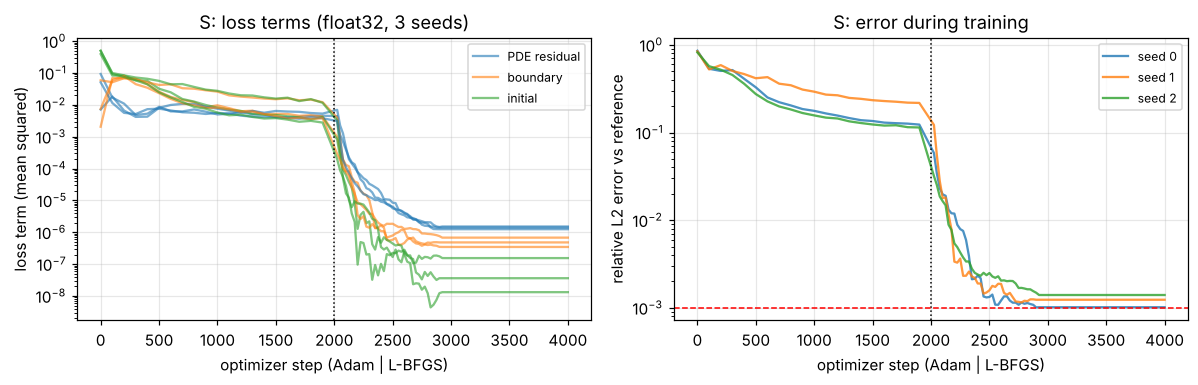

In [6]:
def curves(prob, axes):
    for (p, dt, seed), r in sorted(RUNS.items()):
        if p != prob or dt != "float32": continue
        h = r["hist"]; s = np.array(h["step"])
        axes[0].semilogy(s, h["pde"], color="C0", alpha=0.6, label="PDE residual" if seed == 0 else None)
        axes[0].semilogy(s, h["bc"], color="C1", alpha=0.6, label="boundary" if seed == 0 else None)
        axes[0].semilogy(s, h["ic"], color="C2", alpha=0.6, label="initial" if seed == 0 else None)
        axes[1].semilogy(s, h["rel_l2"], alpha=0.8, label=f"seed {seed}")
    for ax in axes:
        ax.axvline(CFG["n_adam"], color="k", ls=":", lw=1)
        ax.set_xlabel("optimizer step (Adam | L-BFGS)")
    axes[0].set_ylabel("loss term (mean squared)"); axes[0].legend(fontsize=8)
    axes[1].set_ylabel("relative L2 error vs reference"); axes[1].legend(fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
curves("S", axes); axes[0].set_title("S: loss terms (float32, 3 seeds)"); axes[1].set_title("S: error during training")
axes[1].axhline(1e-3, color="r", ls="--", lw=1); plt.tight_layout(); plt.show()

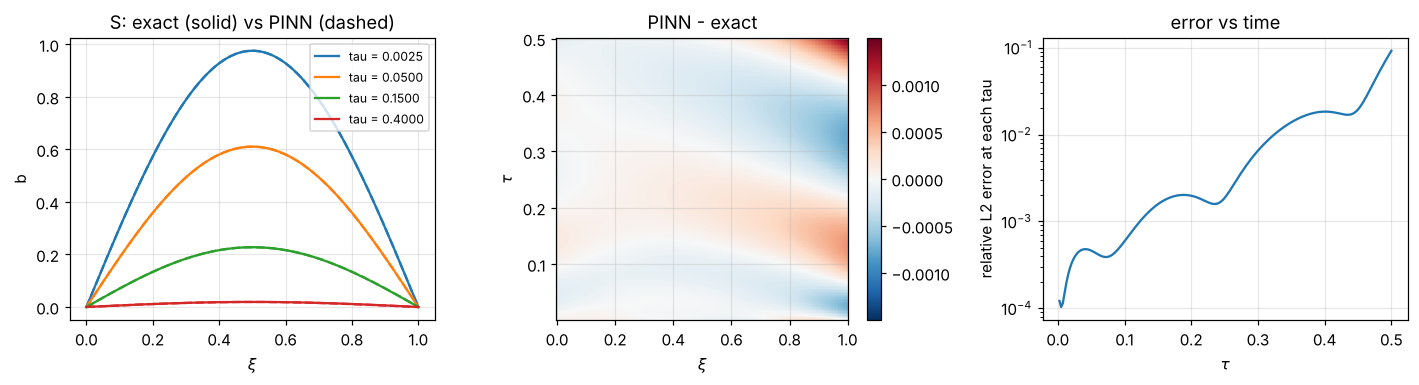

In [7]:
def profiles_and_map(prob, key, taus, fname=None):
    pred = RUNS[key]["pred"].astype(float); ref_ = REF[prob]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    for t in taus:
        k = np.argmin(np.abs(tau_g - t))
        l, = axes[0].plot(xi_g, ref_[k], lw=1.5, label=f"tau = {tau_g[k]:.4f}")
        axes[0].plot(xi_g, pred[k], "--", color=l.get_color(), lw=1.5)
    axes[0].set_title(f"{prob}: exact (solid) vs PINN (dashed)"); axes[0].set_xlabel(r"$\xi$"); axes[0].set_ylabel("b"); axes[0].legend(fontsize=8)
    err = pred - ref_
    vmax = np.abs(err).max()
    im = axes[1].pcolormesh(xi_g, tau_g, err, cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="auto")
    axes[1].set_title("PINN - exact"); axes[1].set_xlabel(r"$\xi$"); axes[1].set_ylabel(r"$\tau$"); plt.colorbar(im, ax=axes[1])
    rel_t = np.linalg.norm(err, axis=1) / np.linalg.norm(ref_, axis=1)
    axes[2].semilogy(tau_g, rel_t); axes[2].set_xlabel(r"$\tau$"); axes[2].set_ylabel("relative L2 error at each tau"); axes[2].set_title("error vs time")
    plt.tight_layout(); plt.show()

profiles_and_map("S", ("S", "float32", 0), [0.0025, 0.05, 0.15, 0.4])

### What S shows

- **The 1e-3 criterion is missed in float32 and met in float64.** The three float32 seeds end at 1.02e-3, 1.24e-3 and 1.40e-3 (median 1.24e-3). The single float64 run ends at 6.6e-4. With one float64 seed this is suggestive, not established.
- **Adam alone is far from enough.** After 2000 Adam steps the relative error is still about 0.1 to 0.2. Almost all of the accuracy comes from L-BFGS, which takes the error down by roughly two orders of magnitude.
- **L-BFGS stalls.** In all three float32 runs the curves go flat from about step 2900, well before the 4000-step budget is used. Float32 round-off in the second derivatives is a plausible cause, and the better float64 result is consistent with it, but this notebook does not test it directly.
- **The error is a smooth, low-amplitude pattern, not a failure.** The largest absolute error is about 1.5e-3 to 2e-3, at the right boundary at late time. The relative error at each time grows with $\tau$ simply because the exact solution decays like $e^{-\pi^2\tau}$: at $\tau = 0.5$ the field is about 0.007, so a small absolute error is a large relative one. The global relative L2 is dominated by early and middle times.
- **The three loss terms fall together** and end near 1e-6 (PDE residual) with the boundary and initial terms at or below that. Nothing here shows the loss-balance conflict that the spec predicts for A.

## 4. Problem A: step at the boundary

Initial condition $b(\xi,0)=0$, boundary $b(0,\tau)=1$, $b(1,\tau)=0$. The initial and boundary data disagree at the corner $(\xi,\tau)=(0,0)$, so the exact solution has a steep front that forms immediately at $\xi=0$. SPEC.md section 8 predicted poor accuracy near $\xi=0$ at small $\tau$.

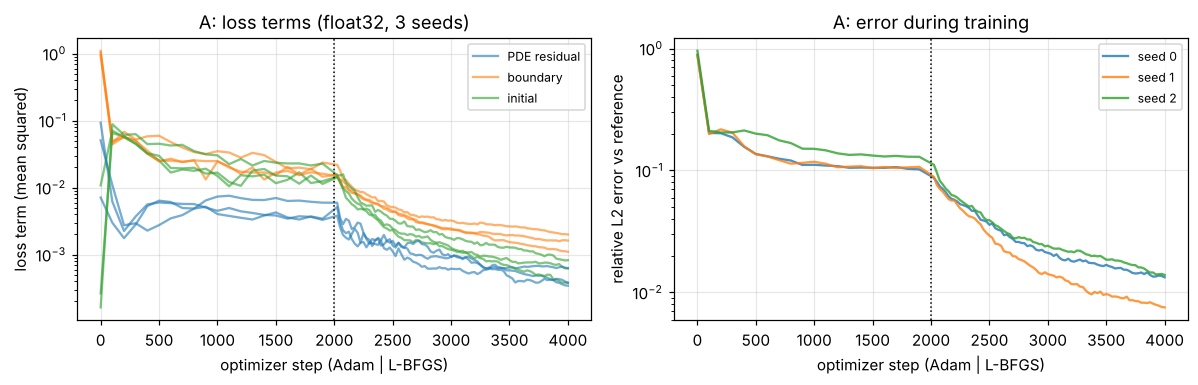

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
curves("A", axes); axes[0].set_title("A: loss terms (float32, 3 seeds)"); axes[1].set_title("A: error during training")
plt.tight_layout(); plt.show()

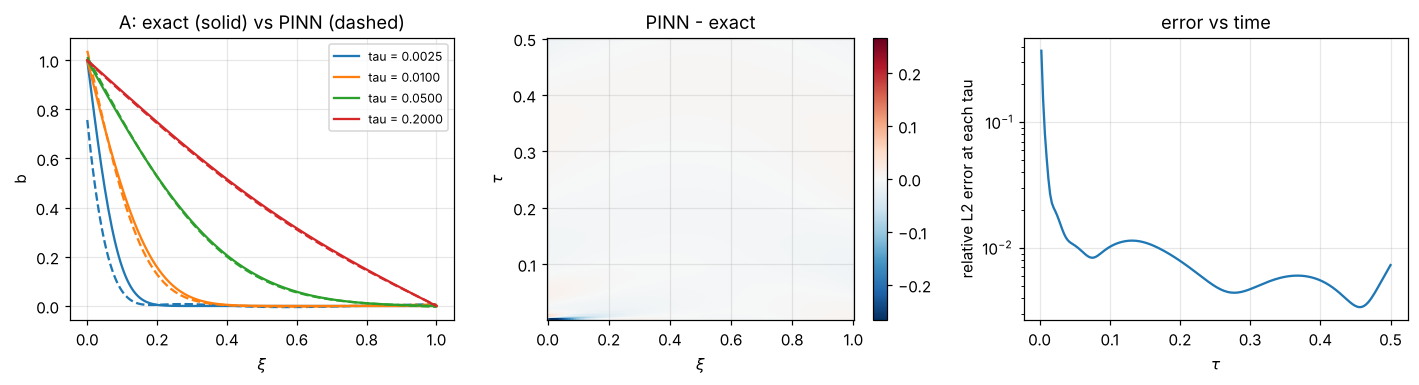

In [9]:
profiles_and_map("A", ("A", "float32", 0), [0.0025, 0.01, 0.05, 0.2])

In [10]:
# Where does the error live? Share of the total squared error in the early-time / near-boundary corner.
for key in [("A", "float32", s) for s in (0, 1, 2)] + [("A", "float64", 0), ("S", "float32", 0)]:
    p = key[0]
    err2 = (RUNS[key]["pred"].astype(float) - REF[p]) ** 2
    T, X = np.meshgrid(tau_g, xi_g, indexing="ij")
    corner = (T <= 0.05) & (X <= 0.2)
    print(key, f"corner (tau<=0.05, xi<=0.2) is {corner.mean():.1%} of the grid and carries {err2[corner].sum()/err2.sum():.1%} of the squared error")

('A', 'float32', 0) corner (tau<=0.05, xi<=0.2) is 2.0% of the grid and carries 70.1% of the squared error
('A', 'float32', 1) corner (tau<=0.05, xi<=0.2) is 2.0% of the grid and carries 59.3% of the squared error
('A', 'float32', 2) corner (tau<=0.05, xi<=0.2) is 2.0% of the grid and carries 77.9% of the squared error
('A', 'float64', 0) corner (tau<=0.05, xi<=0.2) is 2.0% of the grid and carries 48.2% of the squared error
('S', 'float32', 0) corner (tau<=0.05, xi<=0.2) is 2.0% of the grid and carries 0.2% of the squared error


### What A shows

- **The global error looks acceptable but hides a local failure.** Relative L2 error is 7.5e-3 to 1.4e-2 in float32 (median 1.3e-2) and 6.3e-3 in float64, which would pass for many uses. But the squared error is concentrated: the region $\tau \le 0.05$, $\xi \le 0.2$ is 2% of the evaluation grid and carries 59% to 78% of the squared error in float32 (48% in float64).
- **The failure is exactly where the data conflict.** At the earliest evaluation time ($\tau = 0.0025$) the exact boundary value is 1, but the PINN's value at $\xi=0$ is about 0.75 in the seed shown, and the front is too sharp and sits too close to the wall. At $\tau=0.01$ it is much closer; by $\tau = 0.05$ the profiles are hard to tell apart. The largest absolute errors are 0.1 to 0.3, at $\tau \le 0.005$ and $\xi \le 0.02$, compared with at most 2e-3 on S.
- **Low global error is not low residual.** The held-out PDE-residual mean square varies from 5e-4 to 8e-3 in float32, and is 1.25 in the float64 run, against about 1e-6 on S. The float64 run has the lowest relative L2 but the largest residual, so a network can fit the field well overall while its derivatives are badly wrong near the corner. The residual mean square is therefore a useful second metric but should not be compared across runs without looking at where it comes from.
- **Training had not converged.** Unlike S, the error on A is still falling at the end of the L-BFGS budget in all three float32 runs. More iterations would probably lower the global error somewhat, but nothing here shows the corner would be fixed.
- **Seed matters more on A.** The float32 relative error varies by nearly a factor of two across seeds (7.5e-3 to 1.4e-2), compared with 1.0e-3 to 1.4e-3 on S. M3 comparisons need several seeds each, or differences between methods will be indistinguishable from seed noise.

## 5. Summary and what comes next

| Criterion (SPEC.md M2) | Result |
|---|---|
| Relative L2 on S below 1e-3 | **Not met in float32** (1.02e-3 to 1.40e-3 over 3 seeds). Met in float64 for one seed (6.6e-4). |
| Behavior on A documented, including failures | Done: global error about 1%, but most of it comes from the corner at early time, where the boundary condition is violated by about 0.25 in the seed shown. |

The S criterion is narrowly missed rather than far off, and the likely fixes are already on the M3 list. Planned next, each compared against these baselines over several seeds:

1. **Float64 with more seeds** on S, to establish whether precision is the limit rather than the optimizer.
2. **Hard-coded initial and boundary conditions** through an output transformation, which removes the conflicting loss terms at the corner.
3. **Loss weighting and residual-adaptive sampling**, aimed at the early-time corner of A.
4. **Causal training in $\tau$**, so the early-time front is learned before later times.